# BQ1 — Lighting assessment and occupancy-related evidence

## Purpose and responsibility
**Business question:** How much can peak electricity demand be reduced in each zone without compromising lighting comfort?

**Your contribution (Person 1):** establish where lighting contributes to demand, describe operating-hour and power–lux patterns, compare Floor 2 zones, and identify opportunities that merit validation. **Person 2** uses this evidence to build conditional reduction scenarios and recalculate peaks. This notebook does not claim a reduction percentage or confirmed savings.

Run order: **completed cleaning → original lighting baseline → shared input adapter → this assessment**. The supplied workload document is preserved as `README_analytics.txt`.

## Context and methods
The population includes all **33 lighting zones**, with a **Floor 2 deep dive**. March 6–31, 2019 provides calibration; April 2019 provides assessment. A 15-minute interval starts at `Date`, interpreted in Bangkok local time (UTC+7).

### Key assumptions and business implications
- Weekdays **08:00–18:00** are an assumed schedule, not measured occupancy. Outside-hours lighting can support cleaning, research, circulation or security; it is not automatically waste.
- The original baseline accepts **12/15 cleaned readings**. We preserve those values and add separate **15/15 completeness flags** for your friend's strict scenarios. A complete cleaned interval may include interpolation.
- Ambient ceiling lux indicates relative changes, not occupied desk illumination. **500 lux is not used as an activity or comfort eligibility gate.**
- Plug load provides an independent activity clue but can be dominated by unattended devices. The activity labels below are exploratory evidence, not measured presence/absence or occupant counts.
- The Thai thermal-comfort/glare paper supports local comfort validation. Its daylight glare probability (DGP) threshold is not a lux threshold and does not validate an occupancy classifier.

## 1. Load the frozen assessment inputs
Run `python analytics/lighting/prepare_inputs.py` once after cleaning and baseline. The adapter reuses the original baseline calculations, adds calendar/schema/quality fields, checks unique keys, and reconciles April daytime peaks for all zones. It reads the regenerated supporting tables under `data-cleaning/outputs/analytics/`, with no silent legacy fallback.

The input manifest records source paths, hashes, revision and package versions. If it reports changed inputs, rerun the adapter before this notebook.

In [1]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "baseline").is_dir() and (p / "data-cleaning").is_dir())
sys.path.insert(0, str(root / "analytics/lighting"))
from IPython.display import display, Markdown
from assessment import run_assessment, plot_profiles, plot_schedule, plot_lux, plot_activity, write_findings
results = run_assessment()
figure_dir = results["output"] / "lighting_assessment_figures"
figure_dir.mkdir(exist_ok=True)
opportunities = results["opportunities"]
floor2 = opportunities.loc[opportunities.floor.eq(2)].sort_values("zone")
print(f"Assessment covers {len(opportunities)} zones; shared intervals: {len(results['intervals']):,}")
print("Supporting table set:", results["manifest"]["settings"]["supporting_tables"])
print("Baseline reconciliation:", results["manifest"]["baseline_reconciliation"])

Assessment covers 33 zones; shared intervals: 177,408
Supporting table set: data-cleaning/outputs/analytics
Baseline reconciliation: All 33 April operating-hour zone peaks reproduce saved baseline


## 2. Where does lighting contribute to demand?
Compare each zone's lighting contribution **at that zone's own original daytime peak**. A high percentage identifies a load worth understanding; it does not establish a safe controllable percentage. Zone maxima occur at different times and must not be added into a building peak.

,zone,april_peak_time,april_peak_total_kW,lighting_kW_at_peak,lighting_share_at_peak_pct,ambient_lux_at_peak,ambient_lux_missing_at_daytime_zone_peak
4,1,2019-04-17 15:45:00,55.470,8.415,15.170,77.467,False
5,2,2019-04-22 09:45:00,46.938,2.650,5.646,50.733,False
6,3,2019-04-29 11:15:00,2.097,1.097,52.320,4.067,False
7,4,2019-04-22 13:30:00,13.095,1.850,14.127,47.667,False


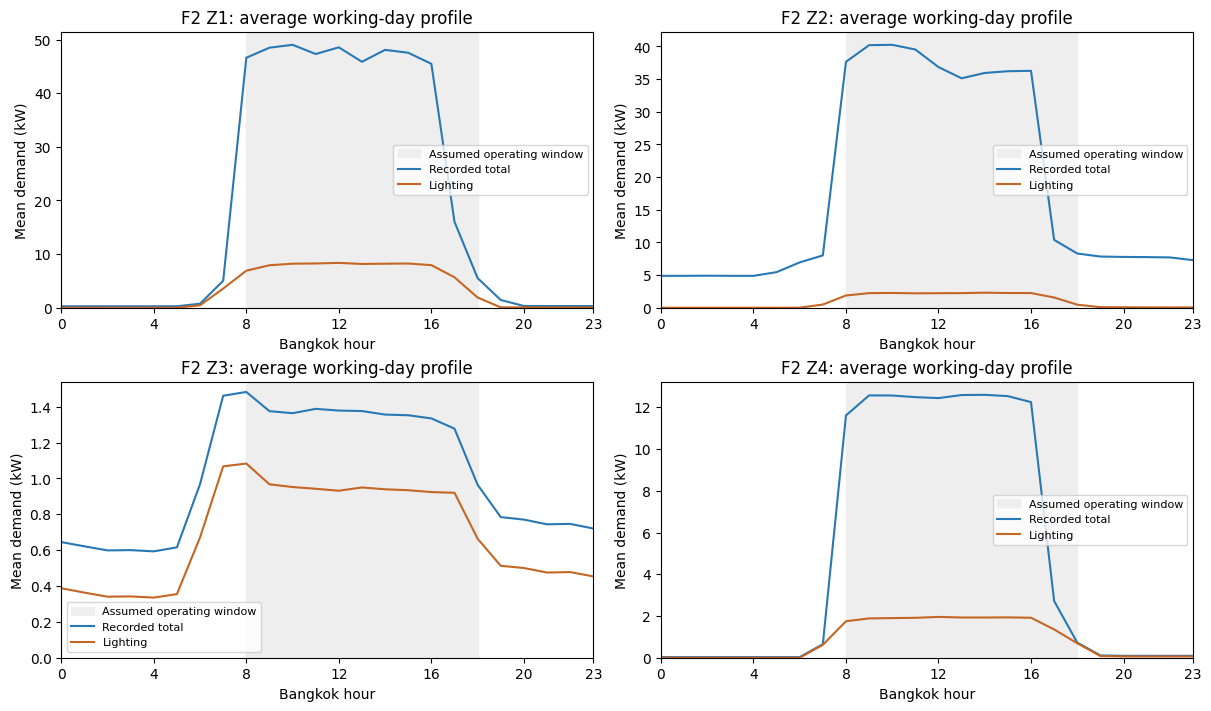

In [2]:
columns = ["zone", "april_peak_time", "april_peak_total_kW", "lighting_kW_at_peak", "lighting_share_at_peak_pct", "ambient_lux_at_peak", "ambient_lux_missing_at_daytime_zone_peak"]
display(floor2[columns].round(3))
plot_profiles(results)

In [3]:
z1 = floor2.loc[floor2.zone.eq(1)].iloc[0]
z3 = floor2.loc[floor2.zone.eq(3)].iloc[0]
display(Markdown(f"**Finding:** Zone 1 has **{z1.lighting_kW_at_peak:.2f} kW** of lighting at its demand peak. Zone 3 has a higher lighting share (**{z3.lighting_share_at_peak_pct:.1f}%**) but only **{z3.lighting_kW_at_peak:.2f} kW** of lighting at its peak. **Recommendation:** give your collaborator both kW and percentage; the percentage alone overstates Zone 3's absolute leverage."))

**Finding:** Zone 1 has **8.41 kW** of lighting at its demand peak. Zone 3 has a higher lighting share (**52.3%**) but only **1.10 kW** of lighting at its peak. **Recommendation:** give your collaborator both kW and percentage; the percentage alone overstates Zone 3's absolute leverage.

**How to read the profiles:** the shaded area is the assumed operating window. Compare start-up, shut-down and overnight lighting with each zone's recorded total demand. Each panel uses its own vertical scale because zone sizes differ. Lines average each measure over its available intervals; they are descriptive profiles, not matched intervention comparisons.

**Business implication:** prioritise substantial lighting kW and credible scheduling evidence together. A small zone can have a high lighting share yet offer little absolute peak leverage.

## 3. Is lighting used outside the assumed schedule?
The chart partitions April energy into normal weekday operating hours, weekday outside hours, weekends, and **inferred closure days**. Closure days take precedence in this chart, so the categories do not overlap. The opportunity table separately reports all energy outside the weekday 08:00–18:00 window; that is a different, explicitly labelled grouping.

**Why this matters:** schedules are an actionable audit target even when the lux readings cannot prove dimming headroom. Review energy alongside valid hours and mean lighting power; a longer segment naturally accumulates more energy.

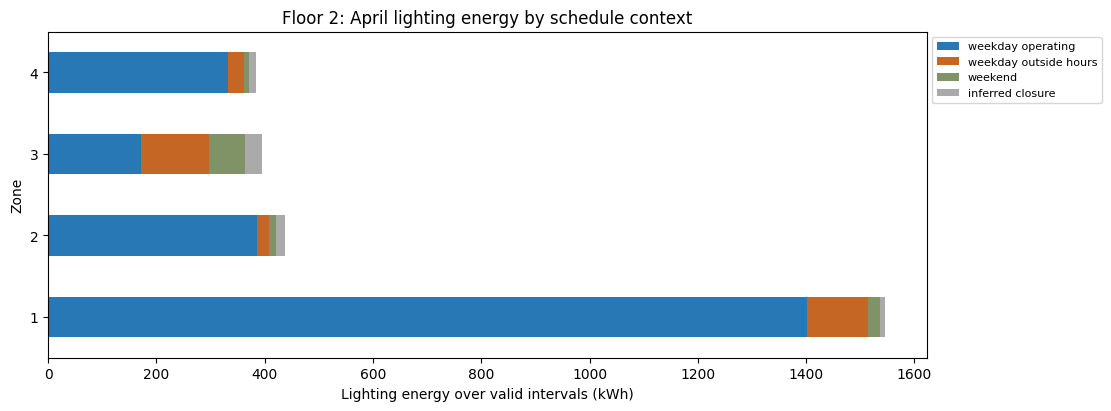

,zone,outside_assumed_hours_lighting_kWh,outside_assumed_hours_energy_share_pct,normal_operating_mean_lighting_kW,outside_hours_mean_lighting_kW,april_all_hours_light_coverage_pct
4,1,139.664,9.038,7.786,0.279,100.0
5,2,43.118,9.875,2.139,0.086,100.0
6,3,208.298,52.628,0.954,0.417,100.0
7,4,46.370,12.084,1.846,0.093,100.0


,zone,schedule_segment,observed_lighting_hours,valid_period_lighting_kWh,mean_lighting_kW,light_coverage_pct
16,1,inferred closure,96.0,9.569,0.100,100.0
17,1,weekday operating,180.0,1401.504,7.786,100.0
18,1,weekday outside hours,252.0,112.574,0.447,100.0
19,1,weekend,192.0,21.637,0.113,100.0
20,2,inferred closure,96.0,15.023,0.156,100.0
21,2,weekday operating,180.0,385.075,2.139,100.0
22,2,weekday outside hours,252.0,22.446,0.089,100.0
23,2,weekend,192.0,14.086,0.073,100.0
24,3,inferred closure,96.0,32.215,0.336,100.0
25,3,weekday operating,180.0,171.736,0.954,100.0


In [4]:
plot_schedule(results)
columns = ["zone", "outside_assumed_hours_lighting_kWh", "outside_assumed_hours_energy_share_pct", "normal_operating_mean_lighting_kW", "outside_hours_mean_lighting_kW", "april_all_hours_light_coverage_pct"]
display(floor2[columns].round(3))
display(results["schedule"].query("floor == 2")[['zone','schedule_segment','observed_lighting_hours','valid_period_lighting_kWh','mean_lighting_kW','light_coverage_pct']].round(3))

In [5]:
display(Markdown(f"**Finding:** Zone 3 records **{z3.outside_assumed_hours_lighting_kWh:.2f} kWh outside assumed hours**, or **{z3.outside_assumed_hours_energy_share_pct:.1f}%** of its valid-period lighting energy. Its mean outside-hours lighting load is **{z3.outside_hours_mean_lighting_kW:.3f} kW**. **Recommendation:** inspect the circuit's purpose and actual attendance before changing its schedule. This is audit exposure, not an estimate of avoidable energy."))

**Finding:** Zone 3 records **208.30 kWh outside assumed hours**, or **52.6%** of its valid-period lighting energy. Its mean outside-hours lighting load is **0.417 kW**. **Recommendation:** inspect the circuit's purpose and actual attendance before changing its schedule. This is audit exposure, not an estimate of avoidable energy.

**Interpretation:** outside-hours energy is an investigation quantity, not recoverable savings. Check whether affected circuits serve occupied research spaces, corridors or essential functions before proposing schedule changes. Energy-derived closure labels cannot independently validate an energy-based occupancy proxy.

## 4. What do lighting power and ambient lux tell us?
The scatter plots separate March/April and daytime/nighttime within each zone. The boxplots summarise the same sensor context by month and time of day; extreme points are omitted from the boxplot display only, not removed from the data.

**Questions to examine:** Does lux rise with lighting power? Does daytime light remain higher at similar electric lighting power? Do patterns change between months? A pooled relationship across zones would confuse different sensor positions and lighting circuits, so each zone is shown separately.

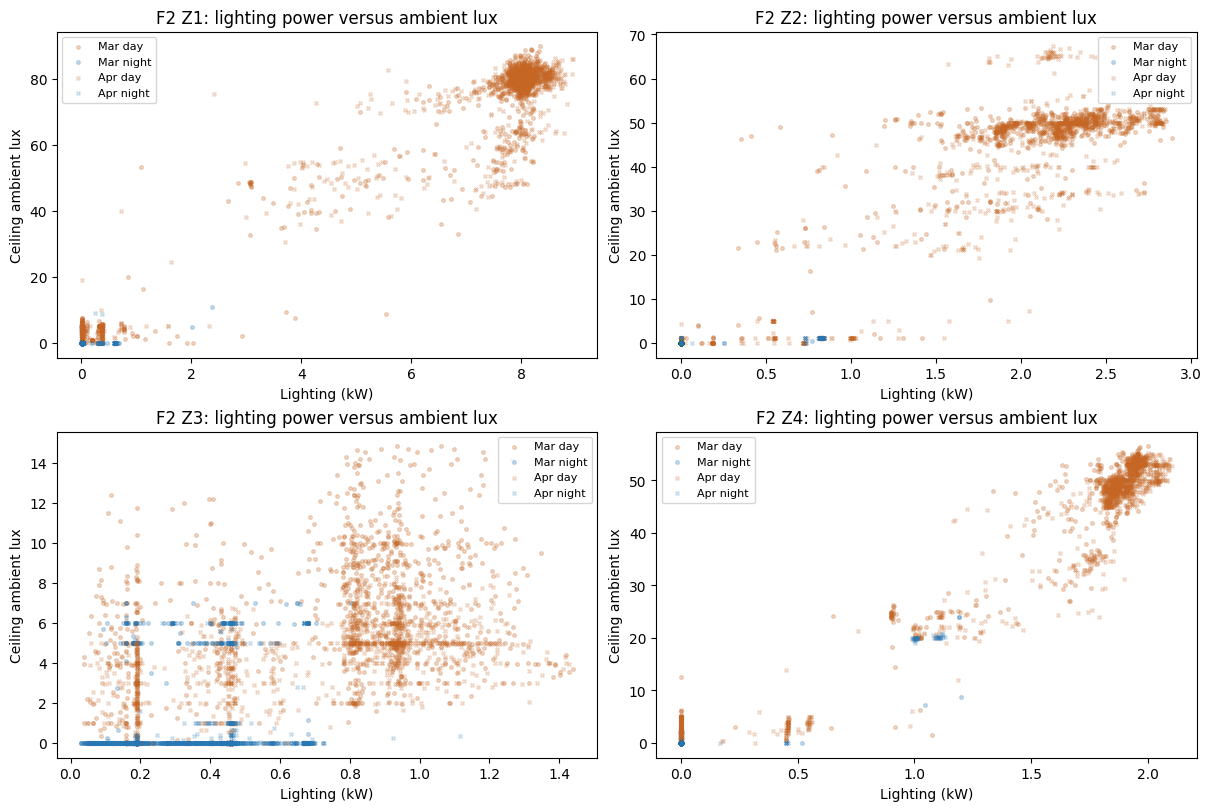

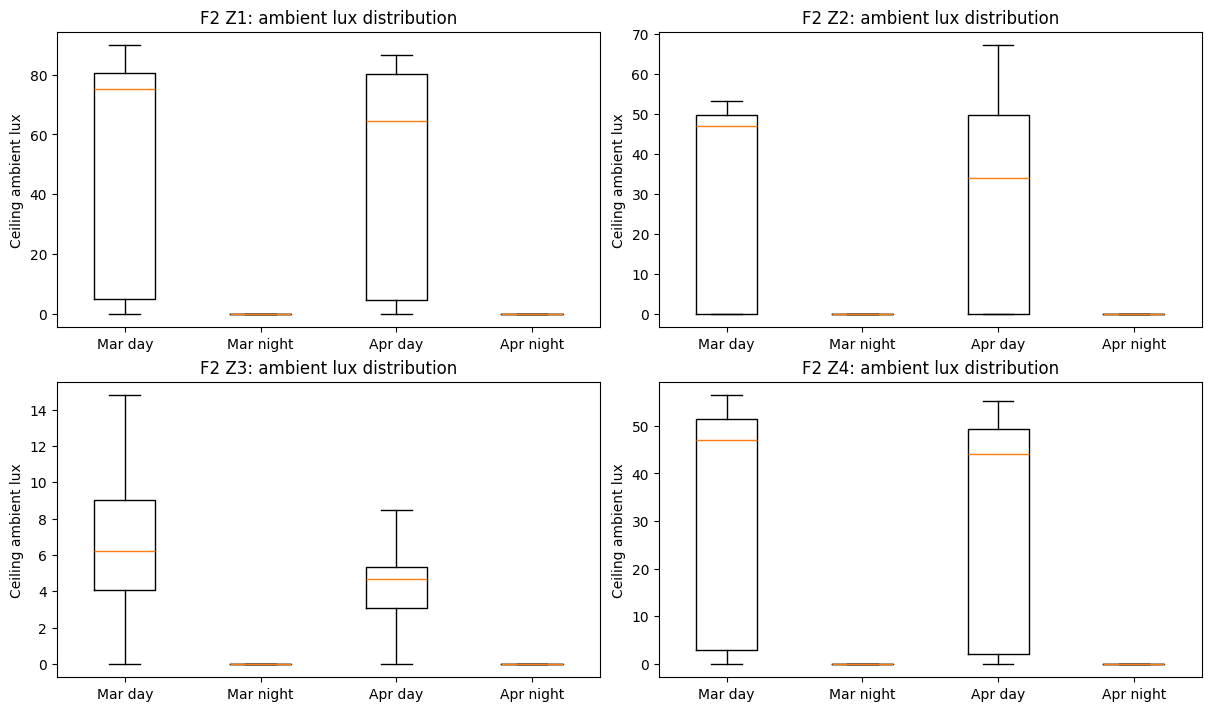

,zone,april_power_lux_spearman,paired_power_lux_intervals,april_max_ambient_lux
4,1,0.731,2872,86.400
5,2,0.962,2846,67.267
6,3,0.555,2839,8.467
7,4,0.902,2850,55.267


In [6]:
plot_lux(results)
display(floor2[["zone", "april_power_lux_spearman", "paired_power_lux_intervals", "april_max_ambient_lux"]].round(3))

In [7]:
z2 = floor2.loc[floor2.zone.eq(2)].iloc[0]
display(Markdown(f"**Finding:** April lighting–lux Spearman correlation is **{z2.april_power_lux_spearman:.2f} in Zone 2**, compared with **{z3.april_power_lux_spearman:.2f} in Zone 3**. The sensors respond differently by zone. **Recommendation:** assess each sensor/circuit separately; these associations do not identify a safe dimming percentage or prove that daylight is sufficient."))

**Finding:** April lighting–lux Spearman correlation is **0.96 in Zone 2**, compared with **0.56 in Zone 3**. The sensors respond differently by zone. **Recommendation:** assess each sensor/circuit separately; these associations do not identify a safe dimming percentage or prove that daylight is sufficient.

### Compare day and night at similar lighting power
Lighting-power bands are defined from March quantiles and frozen before April. A band contributes only when it has at least eight valid daytime and eight valid nighttime observations within the same month. Day is 08:00–18:00; night is 20:00–06:00; transition hours are excluded.

The reported difference is the median of supported bands' daytime-minus-nighttime median lux. This is descriptive matching, not a causal daylight estimate: power still varies within a band, and blinds, schedules and weather remain uncontrolled. A missing estimate means insufficient comparable evidence.

In [8]:
display(results["matched_summary"].query("floor == 2").round(3))
display(results["matched_bands"].query("floor == 2").head(16).round(3))

,floor,zone,month,matched_power_bands,median_matched_day_minus_night_lux,status
8,2,1,2019-03,5,3.133,descriptive paired power bands
9,2,1,2019-04,5,3.933,descriptive paired power bands
10,2,2,2019-03,1,0.000,descriptive paired power bands
11,2,2,2019-04,2,14.250,descriptive paired power bands
12,2,3,2019-03,7,4.400,descriptive paired power bands
13,2,3,2019-04,7,3.133,descriptive paired power bands
14,2,4,2019-03,1,1.867,descriptive paired power bands
15,2,4,2019-04,2,8.567,descriptive paired power bands


,floor,zone,month,power_band,day_n,night_n,day_median_lux,night_median_lux,day_minus_night_lux,day_mean_light_kW,night_mean_light_kW
0,2,1,2019-03,"(0.0036699999999999997, 0.01]",71,252,3.467,0.0,3.467,0.010,0.010
1,2,1,2019-03,"(0.01, 0.0107]",93,353,2.867,0.0,2.867,0.011,0.011
2,2,1,2019-03,"(0.0107, 0.0113]",52,242,3.133,0.0,3.133,0.011,0.011
3,2,1,2019-03,"(0.0113, 0.308]",51,118,1.867,0.0,1.867,0.084,0.031
4,2,1,2019-03,"(0.308, 3.738]",63,43,5.000,0.0,5.000,1.396,0.438
5,2,1,2019-04,"(0.0036699999999999997, 0.01]",100,284,3.700,0.0,3.700,0.010,0.010
6,2,1,2019-04,"(0.01, 0.0107]",127,370,3.933,0.0,3.933,0.011,0.011
7,2,1,2019-04,"(0.0107, 0.0113]",75,244,4.000,0.0,4.000,0.011,0.011
8,2,1,2019-04,"(0.0113, 0.308]",63,248,3.533,0.0,3.533,0.037,0.015
9,2,1,2019-04,"(0.308, 3.738]",107,48,4.667,0.0,4.667,0.602,0.570


**Business implication:** a positive matched difference is a reason to investigate daylight-responsive controls, not proof that fixtures can be dimmed. A near-zero difference or insufficient matched support means daylight headroom has not been demonstrated. Task-plane measurements and fixture-response tests are still required.

## 5. Occupancy consideration: identify activity evidence without an occupancy sensor
We fit lighting and plug operating states **separately in March**, then freeze the boundaries. Deterministic two-means is accepted only with >=80% calibration coverage, >=96 valid intervals, >=10% observations in each cluster, separation >=2 pooled standard deviations, and >=0.02 kW between low-cluster p95 and high-cluster p05. These are modelling assumptions, not established occupancy standards. Intermediate or unsupported states remain unknown.

A candidate audit episode requires **lighting high + plug activity low for 60 trailing minutes**. Missing readings or repaired state inputs break persistence when repair provenance is available. We do not use lux alone to infer presence: daylight can change independently of occupancy, and lights can remain on after departure.

**Decision:** check candidates against actual attendance before calling them unnecessary lighting. Flat plug loads cannot support the same inference.

,zone,measure,n,low_kW,high_kW,separation,calibration_coverage_pct,status
8,1,light,2496,2.648,4.802,8.224,100.000,supported
9,1,plug,2496,0.636,2.345,9.634,100.000,supported
10,2,light,2495,0.255,1.407,7.312,99.960,supported
11,2,plug,2492,0.171,0.305,3.744,99.840,supported
12,3,light,2496,0.475,0.672,4.094,100.000,supported
13,3,plug,2495,0.280,0.310,2.852,99.960,supported
14,4,light,2485,0.000,1.002,6.803,99.559,supported
15,4,plug,2492,NaN,NaN,NaN,99.840,no distinct operating states


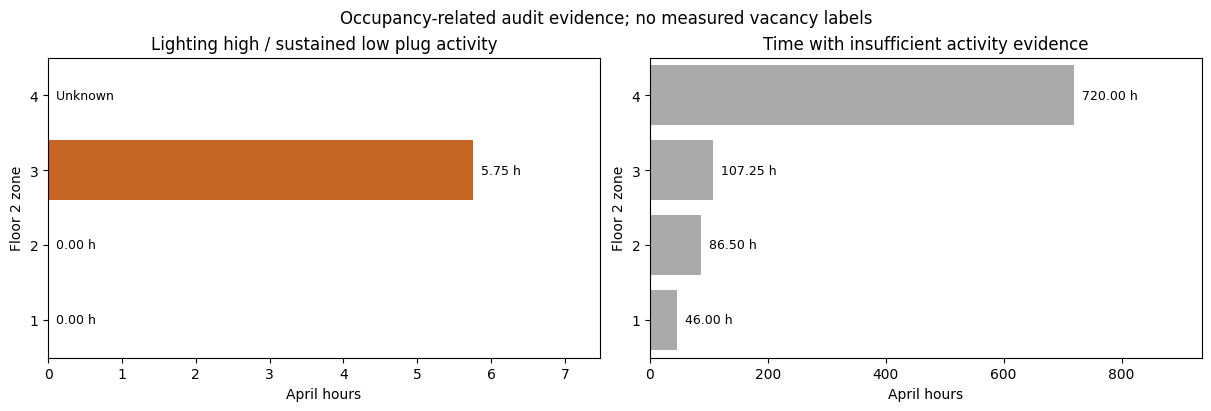

,zone,activity_calibration_supported,activity_mismatch_hours,unknown_activity_hours,plug_baseline_status
4,1,True,0.00,46.00,supported
5,2,True,0.00,86.50,supported
6,3,True,5.75,107.25,supported
7,4,False,NaN,720.00,no distinct operating states


In [9]:
display(results["thresholds"].query("floor == 2")[["zone","measure","n","low_kW","high_kW","separation","calibration_coverage_pct","status"]].round(3))
plot_activity(results)
display(floor2[["zone","activity_calibration_supported","activity_mismatch_hours","unknown_activity_hours","plug_baseline_status"]].round(3))

### Is the finding sensitive to the activity rule?
Compare 30/60/90 minutes of persistence and boundary shifts of ±10% of the March deadband. These are sensitivity assumptions, not confidence intervals or classification accuracy. Unsupported calibrations remain missing rather than becoming zero opportunity.

In [10]:
sensitivity = results["sensitivity"].query("floor == 2")
display(sensitivity.pivot_table(index=["zone","persistence_minutes"],columns="boundary_shift_fraction",values="candidate_hours",dropna=False).round(2))

boundary_shift_fraction    -0.1   0.0   0.1
zone persistence_minutes                   
1    30                    0.00  0.00  0.00
     60                    0.00  0.00  0.00
     90                    0.00  0.00  0.00
2    30                    0.50  0.50  0.75
     60                    0.00  0.00  0.00
     90                    0.00  0.00  0.00
3    30                   21.25  9.75  3.00
     60                   16.50  5.75  0.75
     90                   13.75  4.00  0.00
4    30                     NaN   NaN   NaN
     60                     NaN   NaN   NaN
     90                     NaN   NaN   NaN

## 6. Is the evidence sufficient to act?
Inspect calibration and evaluation coverage separately. Sensor absence differs from a reporting outage. The baseline peak table reports whether lux was available at the demand peak, while the coverage table distinguishes 80%-compatible readings from complete cleaned intervals.

**Comfort boundary:** neither power–lux correlation nor activity evidence proves that a user has enough light. The research paper used occupant feedback and eye-level/HDR glare measurements that this dataset does not contain.

In [11]:
display(results["coverage"].query("floor == 2").round(2))
display(floor2[["zone","evidence_strength","suggested_investigation","sensor_context_warning"]])

,floor,zone,month,expected_intervals,has_lux_sensor,has_plug_meter,total_coverage_pct,light_coverage_pct,lux_coverage_pct,paired_valid_pct,power_complete_pct,paired_complete_pct,repair_free_power_complete_pct
8,2,1,2019-03,2496,True,True,100.0,100.0,97.04,97.04,100.0,96.88,100.00
9,2,1,2019-04,2880,True,True,99.9,100.0,99.72,99.72,99.9,99.65,99.86
10,2,2,2019-03,2496,True,True,100.0,100.0,97.48,97.48,100.0,97.48,99.44
11,2,2,2019-04,2880,True,True,99.9,100.0,98.82,98.82,99.9,98.68,99.48
12,2,3,2019-03,2496,True,True,100.0,100.0,98.88,98.88,100.0,98.68,99.96
13,2,3,2019-04,2880,True,True,100.0,100.0,98.58,98.58,100.0,98.51,100.00
14,2,4,2019-03,2496,True,True,100.0,100.0,82.85,82.85,100.0,82.41,99.44
15,2,4,2019-04,2880,True,True,99.9,100.0,98.96,98.96,99.9,98.82,99.48


,zone,evidence_strength,suggested_investigation,sensor_context_warning
4,1,paired power/ambient evidence; comfort unvalid...,Audit schedules and validate task-plane lighti...,No sensor data 12-15 Sep 2018 to 6 Mar 2019 (b...
5,2,paired power/ambient evidence; comfort unvalid...,Audit schedules and validate task-plane lighti...,No sensor data 12-15 Sep 2018 to 6 Mar 2019 (b...
6,3,paired power/ambient evidence; comfort unvalid...,Review lighting-high/low-plug episodes against...,No sensor data 12-15 Sep 2018 to 6 Mar 2019 (b...
7,4,paired power/ambient evidence; comfort unvalid...,Audit schedules and validate task-plane lighti...,No sensor data 12-15 Sep 2018 to 6 Mar 2019 (b...


## 7. Zone opportunity table and business recommendations
`lighting_opportunities.csv` retains all 33 zones, including power-only and insufficient-evidence zones. Its audit order sorts **observed outside-hours lighting kWh**, not estimated savings or an invented confidence score. Compare the order with coverage, lighting at peak, activity uncertainty and site function before prioritising a visit.

The table is the handoff to Person 2: it supplies evidence and limitations, **not an approved reduction fraction**.

In [12]:
columns = ["floor","zone","lighting_kW_at_peak","outside_assumed_hours_lighting_kWh","outside_assumed_hours_energy_share_pct","april_all_hours_lux_coverage_pct","activity_mismatch_hours"]
labels = {"floor":"Floor","zone":"Zone","lighting_kW_at_peak":"Lighting at peak (kW)","outside_assumed_hours_lighting_kWh":"Outside-hours kWh","outside_assumed_hours_energy_share_pct":"Outside-hours share (%)","april_all_hours_lux_coverage_pct":"Lux coverage (%)","activity_mismatch_hours":"Candidate hours"}
display(opportunities[columns].head(12).rename(columns=labels).round(2))
display(floor2[["zone","evidence_strength","suggested_investigation"]].rename(columns={"zone":"Zone","evidence_strength":"Evidence","suggested_investigation":"Recommended investigation"}))
print("All 33 zones exported to:", results["output"] / "lighting_opportunities.csv")
write_findings(results)

,Floor,Zone,Lighting at peak (kW),Outside-hours kWh,Outside-hours share (%),Lux coverage (%),Candidate hours
3,1,4,38.78,9511.29,98.08,0.00,NaN
2,1,3,51.12,9346.74,70.00,0.00,78.00
1,1,2,36.98,3852.22,66.26,0.00,8.75
0,1,1,12.13,3049.31,98.11,0.00,NaN
24,6,2,6.55,699.13,39.76,97.92,61.00
32,7,5,5.45,398.38,31.84,97.71,NaN
31,7,4,4.41,378.91,36.66,99.03,5.75
9,3,2,6.45,355.46,24.87,73.96,20.75
16,4,4,3.37,353.42,37.61,99.27,11.50
29,7,2,2.84,287.52,35.58,99.06,72.25


,Zone,Evidence,Recommended investigation
4,1,paired power/ambient evidence; comfort unvalid...,Audit schedules and validate task-plane lighti...
5,2,paired power/ambient evidence; comfort unvalid...,Audit schedules and validate task-plane lighti...
6,3,paired power/ambient evidence; comfort unvalid...,Review lighting-high/low-plug episodes against...
7,4,paired power/ambient evidence; comfort unvalid...,Audit schedules and validate task-plane lighti...


All 33 zones exported to: /Users/xiangyingg/Documents/GitHub/SBA-Final-Project/analytics/lighting/outputs/lighting_opportunities.csv


### Floor 2 recommendations
- **Zones 1 and 2:** if the primary rule finds no mismatch, report that result. Do not manufacture savings by reducing the comfort target. Their demand/lighting contribution still informs Person 2's scenario prioritisation.
- **Zone 3:** validate its use and plug standby behaviour before interpreting the small mismatch signal as vacancy. The low absolute lighting load limits the scale of any possible demand benefit.
- **Zone 4:** near-constant plug load leaves occupancy-related activity unassessed. Obtain attendance/booking evidence or a short manual observation study.
- **All zones:** verify essential/circulation lighting, occupied task-plane lux and occupant feedback before any change. Audit schedules first where evidence supports investigation; use a controlled pilot only after the measurement gaps are resolved.

These recommendations are grounded in the executed tables; the final summary below prints the current quantities for review after any rerun.

In [13]:
print("Current Floor 2 assessment:")
for row in floor2.itertuples():
    activity = "unknown" if not row.activity_calibration_supported else f"{row.activity_mismatch_hours:.2f} candidate hours"
    print(f"Zone {row.zone}: {row.outside_assumed_hours_lighting_kWh:.2f} kWh outside assumed hours; {activity}; {row.unknown_activity_hours:.2f} h unknown activity.")
assert len(opportunities) == 33
assert not results["intervals"].duplicated(["Date","floor","zone"]).any()
assert (results["april"].loc[results["april"].activity_mismatch,"plug_state"] == "low").all()
print("Verified: all zones retained, unique interval keys, independent plug evidence for every candidate.")
print("Findings and recommendations:", root / "analytics/lighting" / "lighting_findings.md")

Current Floor 2 assessment:
Zone 1: 139.66 kWh outside assumed hours; 0.00 candidate hours; 46.00 h unknown activity.
Zone 2: 43.12 kWh outside assumed hours; 0.00 candidate hours; 86.50 h unknown activity.
Zone 3: 208.30 kWh outside assumed hours; 5.75 candidate hours; 107.25 h unknown activity.
Zone 4: 46.37 kWh outside assumed hours; unknown; 720.00 h unknown activity.
Verified: all zones retained, unique interval keys, independent plug evidence for every candidate.
Findings and recommendations: /Users/xiangyingg/Documents/GitHub/SBA-Final-Project/analytics/lighting/lighting_findings.md


## Handoff and references
Person 2 should use the shared table and original baseline, distinguish strict complete intervals from baseline-compatible coverage, and recompute scenario peaks over common timestamps. Their responsibility includes reduction fractions, conditional kW/%/kWh, peak shifts and building coincidence. No such simulation is included here.

Sources: supplied `README_analytics.txt`; original `baseline/lighting_peak_baseline.ipynb`; selected cleaning outputs and source manifest; [CU-BEMS dataset paper](https://doi.org/10.1038/s41597-020-00582-3); [Chaloeytoy & Ichinose (2020)](https://digital.car.chula.ac.th/nakhara/vol19/iss1/6/).

The research studied seven Bangkok office buildings and window-facing occupants. It informs local visual/thermal comfort validation, not a transferable occupancy rule or a lux-based DGP calculation.